<a href="https://colab.research.google.com/github/thuongle825/Problem-Set-1-/blob/main/ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

The household: Dana is a single parent wokring full-time as a warehouse associate at the client's distribution center, paid close to the starting wage. Dana rents a two-bedroom apartemnt for herself and her seven year old, and moved into it on a new lease in 2024. She commutes about 20 miles each in a used car because the site isn't served by transit. The monthly budget is dominated by rent, groceries for two, the car, childcare, and utilites, with little left to spend.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [47]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    # {"Item": ..., "Price_2019": ..., "Price_2024": ..., "weight": ...},
    {"Item": "Rent (2BR)", "Price_2019": 1150, "Price_2024": 1480, "weight": 0.39},
    {"Item": "Food at home (2)", "Price_2019": 480, "Price_2024": 600, "weight": 0.16},
    {"Item": "Used car payment", "Price_2019": 300, "Price_2024": 400, "weight": 0.10},
    {"Item": "Gasoline", "Price_2019": 210, "Price_2024": 265, "weight": 0.07},
    {"Item": "Auto insurance", "Price_2019": 120, "Price_2024": 175, "weight": 0.04},
    {"Item": "Children", "Price_2019": 500, "Price_2024": 640, "weight": 0.17},
    {"Item": "Utilities", "Price_2019": 200, "Price_2024": 250, "weight": 0.07},
]

In [48]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [49]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # YOUR CODE HERE
    return 100 * sum (item["weight"] * item[current_key] / item[base_key] for item in basket)

In [50]:
# 1. the unweighted average price change across categories
changes = [(item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100
           for item in household_basket]
unweighted = sum(changes) / len(changes)

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
lasp = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted = lasp - 100

# 3. the gap between them
gap = weighted - unweighted

print("Unweighted average change:", round(unweighted, 1), "%")
print("Laspeyres index (2019 = 100):", round(lasp, 1))
print("Gap (weighted minus unweighted):", round(gap, 1), "percentage points")


Unweighted average change: 30.3 %
Laspeyres index (2019 = 100): 128.7
Gap (weighted minus unweighted): -1.6 percentage points


**Why do the two differ, and which would you defend to the client?**

**Answer:** The unweighted average treats every category equally, while the Laspeyres index weights price changes by Dana's 2019 spending. I'd defend the Laspeyres index (28.7%) because it better reflects her actaul budget. Its limitation is that it ignores changes in spending habits and may overstate the true cost increase.



---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [51]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02"]

In [56]:
all_series = {}
for sid in series_ids:
  url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=" + sid
  data = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
  all_series[sid] = data.iloc[:,0]

fred = pd.concat(all_series, axis = 1)
fred.tail()

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |Measues overall inflation across common consumer goods and services. |Uses national averages that may not match my speading or local prices. |
| `CUSR0000SEHA` |Tracks rent increases, a major household expense.|Does not reflect my excat rent or utility costs. |
| `CUSR0000SAF11` | Tracks grocery pices for food consumed at home. | Does not reflect my excat grocery choices or shopping habits. |
| `CUSR0000SETA02` |Track used-car prices if my household buys or owns a used vehicle. | Does not capture fuel insurance, repairs, or public transportation cost.  |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [57]:
# Rebase to 2019 = 100
rebased = pd.DataFrame()
for sid in fred.columns:
  avg_2019 = fred.loc["2019", sid].mean()
  rebased[sid] = fred[sid] / avg_2019 * 100

print(rebased.loc["2019"].mean())

CPIAUCSL          100.0
CUSR0000SEHA      100.0
CUSR0000SAF11     100.0
CUSR0000SETA02    100.0
dtype: float64


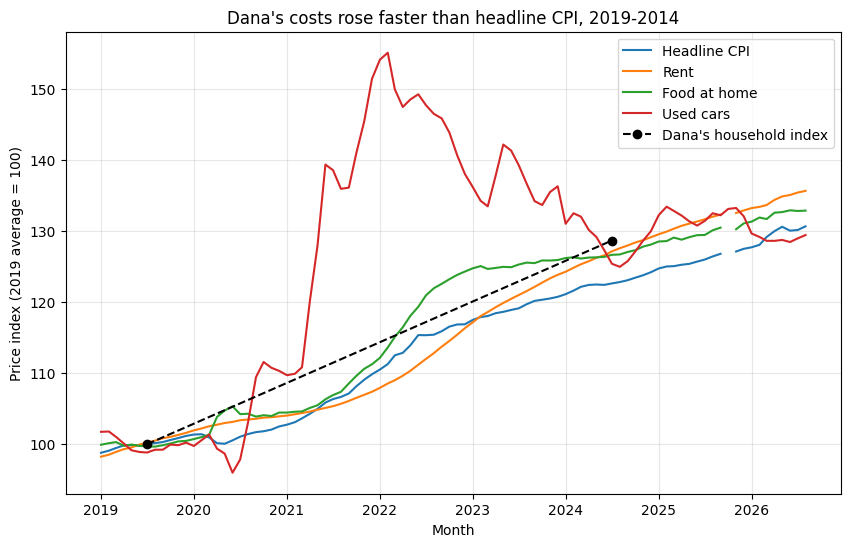

In [63]:
# One chart: every rebased series, plus your household index
recent = rebased.loc["2019":]

labels = {
    "CPIAUCSL": "Headline CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Food at home",
    "CUSR0000SETA02": "Used cars"
}

plt.figure(figsize=(10,6))

for sid in recent.columns:
  plt.plot(recent.index, recent[sid], label=labels[sid])

plt.plot([pd.Timestamp("2019-07-01"), pd.Timestamp("2024-07-01")],
  [100, lasp],
  "ko--", label="Dana's household index")

plt.xlabel("Month")
plt.ylabel("Price index (2019 average = 100)")
plt.title ("Dana's costs rose faster than headline CPI, 2019-2014")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [71]:
# First observation, last observation, frequency and missing months, for every series
audit_rows = []

for sid in fred.columns:
  s = fred[sid].dropna()
  monthly = s.asfreq("MS")
  missing = monthly[monthly.isna()].index

  missing_list = []
  for d in missing:
    missing_list.append(d.strftime("%Y-%m"))

    spacing = s.index.to_series().diff().median().days
    if 28 <= spacing <= 31:
      frequency = "Monthly"
    else:
      frequency = str(spacing) + "days"

    if missing_list:
      missing_text = str(len(missing_list)) + "(" + ", ".join(missing_list)+ ")"
    else: missing_text = "0"

    audit_rows.append({
        "Series": sid,
        "First": s.index.min().strftime("%Y-%m"),
        "Last": s.index.max().strftime("%Y-%m"),
        "Frequency": frequency,
        "Missing months": missing_text
    })

audit = pd.DataFrame(audit_rows)
audit

,Series,First,Last,Frequency,Missing months
0,CPIAUCSL,1947-01,2026-08,Monthly,1(2025-10)
1,CUSR0000SEHA,1981-01,2026-08,Monthly,1(2025-10)
2,CUSR0000SAF11,1952-01,2026-08,Monthly,1(2025-10)


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [85]:
# Start dates side by side, and the common sample
start_rows = []
for sid in fred.columns:
  start_rows.append({
      "Series": sid,
      "Start": fred[sid].first_valid_index(),
      "End": fred[sid].last_valid_index(),
  })
starts = pd.DataFrame(start_rows)
print(starts)

common_start = starts["Start"].max()
common_end = starts["End"].min()
earliest_start = starts["Start"].min()

common_months = len(pd.date_range(common_start, common_end, freq = "MS"))
discarded = len(pd.date_range(earliest_start, common_start, freq = "MS")) -1

print()
print("Common sample start:", common_start.strftime("%Y-%m"))
print("Common sample length:", common_months, "months")
print("Months of the longest series discarded:",discarded)

           Series      Start        End
0        CPIAUCSL 1947-01-01 2026-08-01
1    CUSR0000SEHA 1981-01-01 2026-08-01
2   CUSR0000SAF11 1952-01-01 2026-08-01
3  CUSR0000SETA02 1953-01-01 2026-08-01

Common sample start: 1981-01
Common sample length: 548 months
Months of the longest series discarded: 408


In [93]:
# Headline comparison: full history vs common sample
def annual_rate(s):
  """Average yearly % change from the first to the last value."""
  s = s.dropna()
  months = len(pd.date_range(s.index[0], s.index[-1], freq="MS"))-1
  years = months / 12
  return ((s.iloc[-1] / s.iloc[0]) ** (1 / years) -1 ) * 100

common = fred.loc[common_start:common_end]

full_headline = annual_rate(fred["CPIAUCSL"])
common_rate = annual_rate(common["CPIAUCSL"])

comparison_rows = []
for sid in fred.columns:
    full_rate = annual_rate(fred[sid])
    common_rate = annual_rate(common[sid])
    comparison_rows.append({
        "Series": sid,
        "Full History (%/yr)": round(full_rate, 2),
        "Common sample (%/yr)": round(common_rate, 2),
        "Gap vs headline, full": round(full_rate - full_headline, 2),
        "Gap vs headline, common": round(common_rate - common_rate, 2)
    })

comparison = pd.DataFrame(comparison_rows)
comparison

,Series,Full History (%/yr),Common sample (%/yr),"Gap vs headline, full","Gap vs headline, common"
0,CPIAUCSL,3.51,2.99,0.00,0.0
1,CUSR0000SEHA,3.73,3.73,0.22,0.0
2,CUSR0000SAF11,3.18,2.75,-0.33,0.0
3,CUSR0000SETA02,2.53,2.10,-0.97,0.0


**What restricting to the common sample assumes, and what not restricting assumes:**

**Answer:** Restricting to the common sample (1981 onward) assumes that the years every series shares are representative, so leaving out 1947-1980 from headline CPI, food at home and used cars does not change the conclusion about which costs rise faster for workers today.

Not restricting assumes that average inflation rates measured over different eras can be compared directly, even though headline CPI's full history includes the high inflation of the 1970s that rent's history never saw. That assumption shrinks rent's apparent gap over headline from +0.74 to +0.22 points a year.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

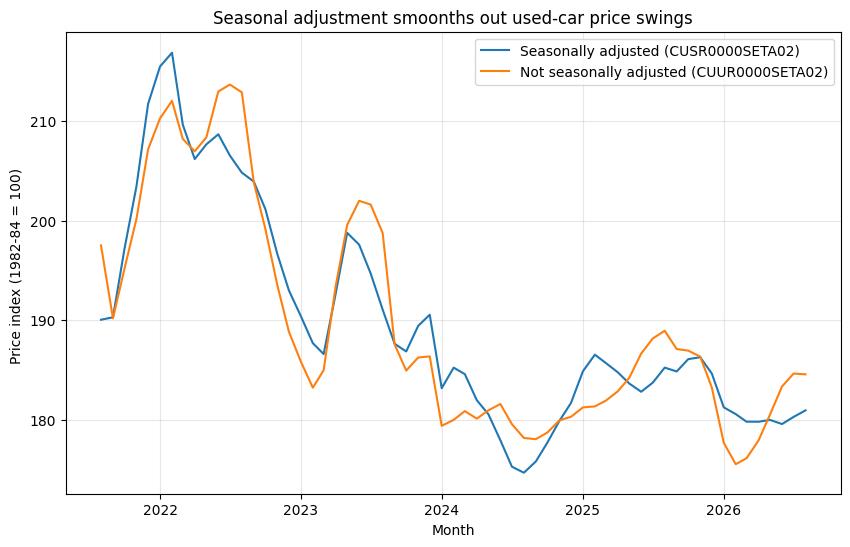

In [111]:
# Seasonally adjusted vs unadjusted, last five years
url= "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CUUR0000SETA02"
nsa_data = pd. read_csv (url, index_col=0, parse_dates=True, na_values=".")
nsa = nsa_data.iloc[:, 0]

sa = fred["CUSR0000SETA02"]
five_years_ago = sa.index.max() - pd.DateOffset(years=5)
sa_recent = sa.loc[five_years_ago:]
nsa_recent = nsa.loc[five_years_ago:]

plt.figure(figsize= (10, 6))
plt.plot(sa_recent. index, sa_recent, label= "Seasonally adjusted (CUSR0000SETA02) ")
plt.plot(nsa_recent.index, nsa_recent, label= "Not seasonally adjusted (CUUR0000SETA02)")
plt.xlabel ("Month")
plt. ylabel("Price index (1982-84 = 100) ")
plt.title("Seasonal adjustment smoonths out used-car price swings")
plt. legend()
plt.grid(alpha=0.3)
plt. show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

**Answer:** The model was right that the gap between adjusted and unadjusted prices reflects estimated seasonal effects, not prices anyone paid. I checked the BLS methodology to confirm this. However, annual averaging does not guarantee that adjusted and unadjusted series show the same percentage change, so both must be calculated to verify the comparison. I also removed the explanation attributing seasonal price movements to tax refunds and demand because it was unsupported.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Baseline index (2019 = 100): 128.70
            Item  base_weight  pct_price_change  points_per_0.10_weight  share_of_change
  Auto insurance         0.04            45.833                   1.785            0.064
Used car payment         0.10            33.333                   0.515            0.116
Food at home (2)         0.16            25.000                  -0.441            0.139
       Utilities         0.07            25.000                  -0.398            0.061
        Gasoline         0.07            26.190                  -0.270            0.064
        Children         0.17            28.000                  -0.084            0.166
      Rent (2BR)         0.39            28.696                  -0.001            0.390


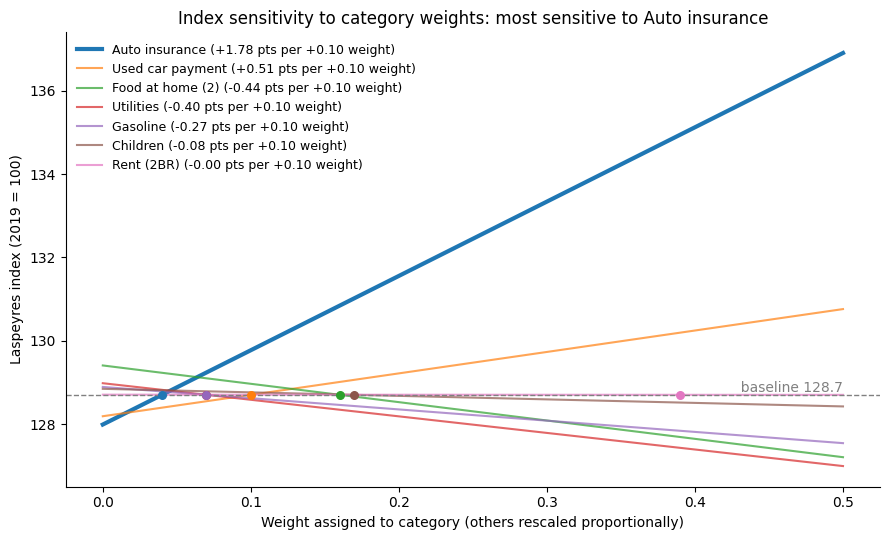

In [112]:
# Paste the AI's code here, run it, and correct it where it is wrong

# Weight-sensitivity sweep for the household Laspeyres index
# Assumes household_basket already exists: a list of dicts with keys
# Item, Price_2019, Price_2024, weight
# Assumes `weight` is a base-period (2019) EXPENDITURE SHARE. If your weights are
# quantities instead, the index formula below must change to
# sum(P2024 * q) / sum(P2019 * q).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Set up the basket
# ---------------------------------------------------------------
basket_df = pd.DataFrame(household_basket)
basket_df["relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]

# Normalise so weights sum to exactly 1 (protects against percent entry or rounding).
basket_df["weight"] = basket_df["weight"] / basket_df["weight"].sum()

items = basket_df["Item"].tolist()
relatives = basket_df["relative"].to_numpy()
base_weights = basket_df["weight"].to_numpy()


def laspeyres_index(relatives, weights):
    # Expenditure-share Laspeyres: 100 * sum(w_i * P2024_i / P2019_i)
    return 100 * np.sum(weights * relatives)


baseline_index = laspeyres_index(relatives, base_weights)
print(f"Baseline index (2019 = 100): {baseline_index:.2f}")

# ---------------------------------------------------------------
# 2. Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
# WHY RENORMALISE THE OTHER WEIGHTS?
# A Laspeyres index is a weighted AVERAGE of price relatives, which only holds
# if the weights sum to 1. If we raised one weight without lowering the others,
# the weights would sum to more than 1 and the index would rise mechanically,
# even with no change in any price. That would measure "a bigger basket", not
# "a different mix of spending". Scaling the other weights by (1 - w_k) / (1 - w_k_original)
# keeps the total at 1 AND keeps the other categories in the same proportions to
# each other, so the only thing that changes is the target category's share.

sweep_values = np.linspace(0, 0.5, 51)
sweep_results = {}
slopes = {}

for k in range(len(items)):
    other_total = 1 - base_weights[k]
    if other_total == 0:
        print(f"Skipping {items[k]}: it holds the entire basket weight.")
        continue

    index_values = []
    for w_k in sweep_values:
        new_weights = base_weights.copy()
        for j in range(len(items)):
            if j != k:
                new_weights[j] = base_weights[j] / other_total * (1 - w_k)
        new_weights[k] = w_k
        index_values.append(laspeyres_index(relatives, new_weights))

    sweep_results[items[k]] = index_values
    # The index is linear in w_k, so the slope is constant: endpoints are enough.
    slopes[items[k]] = (index_values[-1] - index_values[0]) / (sweep_values[-1] - sweep_values[0])

# ---------------------------------------------------------------
# 3. Summary table
# ---------------------------------------------------------------
# Two different questions, two different numbers:
#   points_per_0.10_weight -> how much the index moves if this weight is off by 10 pp
#                             (sensitivity to WEIGHT uncertainty)
#   share_of_change        -> how much of the measured inflation this category
#                             contributes at the actual weights (what DRIVES the result)
total_change = np.sum(base_weights * (relatives - 1))

summary_rows = []
for k in range(len(items)):
    if items[k] not in slopes:
        continue
    if total_change != 0:
        share = base_weights[k] * (relatives[k] - 1) / total_change
    else:
        share = np.nan
    summary_rows.append({
        "Item": items[k],
        "base_weight": base_weights[k],
        "pct_price_change": 100 * (relatives[k] - 1),
        "points_per_0.10_weight": slopes[items[k]] * 0.10,
        "share_of_change": share,
    })

summary_df = pd.DataFrame(summary_rows)
summary_df["abs_sensitivity"] = summary_df["points_per_0.10_weight"].abs()
summary_df = summary_df.sort_values("abs_sensitivity", ascending=False)
print(summary_df.drop(columns="abs_sensitivity").round(3).to_string(index=False))

most_sensitive = summary_df["Item"].iloc[0]

# ---------------------------------------------------------------
# 4. Chart: one line per category, steepest line = most sensitive
# ---------------------------------------------------------------
# WHAT IF THE INDEX IS HIGHLY SENSITIVE TO ONE CATEGORY?
# The slope equals 100 * (that category's relative - the weighted average relative
# of everything else). A steep line means that category's price moved very
# differently from the rest of the basket. Then the headline number depends heavily
# on how much this household actually spends there: a small error in that one
# weight shifts the result a lot, and households with a different spending mix
# would experience noticeably different inflation from the "average" figure.

fig, ax = plt.subplots(figsize=(9, 5.5))

for item in summary_df["Item"]:
    k = items.index(item)
    is_top = item == most_sensitive
    label = f"{item} ({slopes[item] * 0.10:+.2f} pts per +0.10 weight)"
    line, = ax.plot(
        sweep_values,
        sweep_results[item],
        linewidth=3 if is_top else 1.5,
        alpha=1.0 if is_top else 0.7,
        label=label,
    )
    # Mark where the household's actual weight sits on each line
    ax.scatter([base_weights[k]], [baseline_index], color=line.get_color(), zorder=3, s=30)

ax.axhline(baseline_index, color="grey", linestyle="--", linewidth=1)
ax.text(0.5, baseline_index, f"  baseline {baseline_index:.1f}", va="bottom", ha="right", color="grey")

ax.set_xlabel("Weight assigned to category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weights: most sensitive to {most_sensitive}")
ax.legend(frameon=False, fontsize=9, loc="best")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

**What the model got right:** The sweep code is mathematically correct: its baseline (128.70) matches my laspeyres () from Step 1.2, the rescaled weights sum to 1, and a hand calculation confirms auto insurance's slope (about +1.78 points per 0.10 of weight). But the interpretation needed checking.
Auto insurance is the most sensitive category, while rent accounts for about 39% of the measured increase. Rent's sensitivity is near zero because its 28.7% price rise is close to the basket average. For the client, the finding is robust to rent spending and moderately sensitive to insurance spending.

**What it got wrong:** Despite being asked to reuse my variable names, it created a second function, laspeyres_index, and silently renormalised the weights, potentially hiding an input error rather than flagging it.

### AI Transcript

**Model:** Claude ~ Opus 5.5 ; **Date:** 10/9

**Prompt:**
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.


**Model Reply:**
The script uses plain loops throughout, keeps household_basket, and assumes weight is a 2019 expenditure share. If your weights are quantities, the index formula has to change. There’s a comment flagging this at the top of the file.

On the Evaluate step: I can’t tell you which category dominates, because I haven’t seen your prices or weights. If you paste the printed summary table, I’ll check your reading of it. Here is how to read it when you run it.

Steepest line means most sensitive. Each line is exactly linear. Its slope is the gap between that category’s price relative and the weighted average of all the other categories. So the most sensitive category isn’t necessarily the one with the biggest weight. It’s the one whose price moved most differently from the rest of the basket. Something like energy or rent can be very sensitive even at a modest weight.

Sensitive is not the same as dominant. The table reports two separate numbers:

points_per_0.10_weight tells you how much the index would change if that weight were wrong by 10 percentage points. This measures risk from uncertainty about the weights.
share_of_change tells you how much of the measured inflation that category actually contributes at your real weights. This measures what drives the result.

A category can top one column and not the other. When you write “dominates,” decide which of the two claims you’re making.

What to tell a client. Something along these lines: “Our index is most sensitive to [category]. Its prices rose [x]% against roughly [y]% for the rest of the basket. Each 10-point shift in its budget share moves the index by about [z] points. A household that spends more than average on [category] has experienced meaningfully higher inflation than our headline figure, and one that spends less has experienced lower inflation. We recommend validating this weight against the household’s actual spending before relying on the number.”

The point is to present it as a statement about whose cost of living the number represents, not as a flaw in the index.

This looks like it’s for PS1. If the problem set’s AI policy limits Claude to critique for this part, check whether generated code is allowed here before you submit it.

**Code that was given:**
# Weight-sensitivity sweep for the household Laspeyres index
# Assumes household_basket already exists: a list of dicts with keys
# Item, Price_2019, Price_2024, weight
# Assumes `weight` is a base-period (2019) EXPENDITURE SHARE. If your weights are
# quantities instead, the index formula below must change to
# sum(P2024 * q) / sum(P2019 * q).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Set up the basket
# ---------------------------------------------------------------
basket_df = pd.DataFrame(household_basket)
basket_df["relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]

# Normalise so weights sum to exactly 1 (protects against percent entry or rounding).
basket_df["weight"] = basket_df["weight"] / basket_df["weight"].sum()

items = basket_df["Item"].tolist()
relatives = basket_df["relative"].to_numpy()
base_weights = basket_df["weight"].to_numpy()


def laspeyres_index(relatives, weights):
    # Expenditure-share Laspeyres: 100 * sum(w_i * P2024_i / P2019_i)
    return 100 * np.sum(weights * relatives)


baseline_index = laspeyres_index(relatives, base_weights)
print(f"Baseline index (2019 = 100): {baseline_index:.2f}")

# ---------------------------------------------------------------
# 2. Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------
# WHY RENORMALISE THE OTHER WEIGHTS?
# A Laspeyres index is a weighted AVERAGE of price relatives, which only holds
# if the weights sum to 1. If we raised one weight without lowering the others,
# the weights would sum to more than 1 and the index would rise mechanically,
# even with no change in any price. That would measure "a bigger basket", not
# "a different mix of spending". Scaling the other weights by (1 - w_k) / (1 - w_k_original)
# keeps the total at 1 AND keeps the other categories in the same proportions to
# each other, so the only thing that changes is the target category's share.

sweep_values = np.linspace(0, 0.5, 51)
sweep_results = {}
slopes = {}

for k in range(len(items)):
    other_total = 1 - base_weights[k]
    if other_total == 0:
        print(f"Skipping {items[k]}: it holds the entire basket weight.")
        continue

    index_values = []
    for w_k in sweep_values:
        new_weights = base_weights.copy()
        for j in range(len(items)):
            if j != k:
                new_weights[j] = base_weights[j] / other_total * (1 - w_k)
        new_weights[k] = w_k
        index_values.append(laspeyres_index(relatives, new_weights))

    sweep_results[items[k]] = index_values
    # The index is linear in w_k, so the slope is constant: endpoints are enough.
    slopes[items[k]] = (index_values[-1] - index_values[0]) / (sweep_values[-1] - sweep_values[0])

# ---------------------------------------------------------------
# 3. Summary table
# ---------------------------------------------------------------
# Two different questions, two different numbers:
#   points_per_0.10_weight -> how much the index moves if this weight is off by 10 pp
#                             (sensitivity to WEIGHT uncertainty)
#   share_of_change        -> how much of the measured inflation this category
#                             contributes at the actual weights (what DRIVES the result)
total_change = np.sum(base_weights * (relatives - 1))

summary_rows = []
for k in range(len(items)):
    if items[k] not in slopes:
        continue
    if total_change != 0:
        share = base_weights[k] * (relatives[k] - 1) / total_change
    else:
        share = np.nan
    summary_rows.append({
        "Item": items[k],
        "base_weight": base_weights[k],
        "pct_price_change": 100 * (relatives[k] - 1),
        "points_per_0.10_weight": slopes[items[k]] * 0.10,
        "share_of_change": share,
    })

summary_df = pd.DataFrame(summary_rows)
summary_df["abs_sensitivity"] = summary_df["points_per_0.10_weight"].abs()
summary_df = summary_df.sort_values("abs_sensitivity", ascending=False)
print(summary_df.drop(columns="abs_sensitivity").round(3).to_string(index=False))

most_sensitive = summary_df["Item"].iloc[0]

# ---------------------------------------------------------------
# 4. Chart: one line per category, steepest line = most sensitive
# ---------------------------------------------------------------
# WHAT IF THE INDEX IS HIGHLY SENSITIVE TO ONE CATEGORY?
# The slope equals 100 * (that category's relative - the weighted average relative
# of everything else). A steep line means that category's price moved very
# differently from the rest of the basket. Then the headline number depends heavily
# on how much this household actually spends there: a small error in that one
# weight shifts the result a lot, and households with a different spending mix
# would experience noticeably different inflation from the "average" figure.

fig, ax = plt.subplots(figsize=(9, 5.5))

for item in summary_df["Item"]:
    k = items.index(item)
    is_top = item == most_sensitive
    label = f"{item} ({slopes[item] * 0.10:+.2f} pts per +0.10 weight)"
    line, = ax.plot(
        sweep_values,
        sweep_results[item],
        linewidth=3 if is_top else 1.5,
        alpha=1.0 if is_top else 0.7,
        label=label,
    )
    # Mark where the household's actual weight sits on each line
    ax.scatter([base_weights[k]], [baseline_index], color=line.get_color(), zorder=3, s=30)

ax.axhline(baseline_index, color="grey", linestyle="--", linewidth=1)
ax.text(0.5, baseline_index, f"  baseline {baseline_index:.1f}", va="bottom", ha="right", color="grey")

ax.set_xlabel("Weight assigned to category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weights: most sensitive to {most_sensitive}")
ax.legend(frameon=False, fontsize=9, loc="best")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

**Answer:** For a single parent who rents and drives to work on the client's starting wage, living costs rose about 29% from 2019 to 2024, roughly 6 points more than the 23% rise in the official consumer price index.
The client's suspicion runs the wrong way. For workers like this, the official index understates what they face rather than overstating it. The reason is where the money goes: rent and childcare take a much larger share of this household's budget than of the average household's, and both rose faster than prices overall. Over the past four decades, rent has risen about 0.7 points a year faster than the official index.
The client can be fairly confident about the direction and less confident about the exact size. The result barely changes if this household spends more or less on rent. It is most affected by car insurance, the fastest-rising cost: misjudging insurance's share of the budget by a tenth would shift our figure by about 2 points. Our method also assumes the household kept buying the same things, so families who cut back on items that got pricier faced slightly less than 29%.
Two limits matter. This describes one type of household, not the whole workforce, and workers who own homes or don't drive will differ. Our prices are also estimates for this household, not a survey of the client's employees.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub